In [ ]:
# 1.Business Scanirio
# Imagine that we work for a retail company managing multuiple warehouses
# The company stores product information, stock levels and historical sales
# The operations team needs to identify products that may run out of stock and preparw
# replenishment recommendations

# Our task is to automate this process using Python
# 2. Tools and technologies
#    1.Python
#    2.Pandas
#    3.Matplotlib
#    4.OpenPyXL
#    5.CSV
#    6.Jupyter or google colab

# Dataset requirements
# products.csv
# product_id,product_name,category,unit_cost,recorder_level

# inventory.csv
# product_id, warehouse_id, availble_quantity

# sales_history.csv
# product_id,sale_date,quantity_sold


In [20]:
# step 1.  import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [143]:
# step 2 load the datasets
import pandas as pd
products= pd.read_csv("/content/products.csv")
inventory=pd.read_csv("/content/inventory.csv")
sales_history=pd.read_csv("/content/sales_history.csv")


In [145]:
# inspect the datasets and clean data
products.head()
inventory.head()
sales_history.head()

# data datatype infromation
products.info()
inventory.info()
sales_history.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   product_id     200 non-null    int64  
 1   product_name   200 non-null    object 
 2   category       200 non-null    object 
 3   unit_cost      200 non-null    float64
 4   reorder_level  200 non-null    int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 7.9+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   product_id          800 non-null    int64
 1   warehouse_id        800 non-null    int64
 2   available_quantity  800 non-null    int64
dtypes: int64(3)
memory usage: 18.9 KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18000 entries, 0 to 17999
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtyp

In [153]:
# Counvert dates
sales= pd.to_datetime(
    sales_history["sale_date"],
    errors="coerce"
)
#convert numerical values
for col in["unit_cost","reorder_level"]:
  products[col]= pd.to_numeric(
    products[col],
    errors="coerce"
)
  inventory["available_quantity"]=pd.to_numeric(
    inventory["available_quantity"],
    errors="coerce"
)

sales["quantity_sold"]=pd.to_numeric(
    sales_history["quantity_sold"],
    errors="coerce"
)



In [154]:
# Check the duplicates
print(
    products.duplicated(
        subset=["product_id"]
    ).sum()
    )
inventory.duplicated(
    subset=["product_id","warehouse_id"]
).sum()





0


np.int64(0)

In [155]:
# Check invelid stock
invalid_stock = inventory[
    inventory["available_quantity"].isna()
    |(inventory["available_quantity"]<0)]

print(invalid_stock)

Empty DataFrame
Columns: [product_id, warehouse_id, available_quantity]
Index: []


In [159]:
end_date = sales_history["sale_date"].max()
start_date = sales_history["sale_date"].min()
recent_sales = sales_history[
    sales_history["sale_date"].between(start_date,end_date)
].copy()

In [160]:
# Aggrigate unit sold
product_sales = products.merge(
    recent_sales.groupby("product_id")["quantity_sold"]
    .sum()
    .reset_index()
)
print(product_sales)

     product_id    product_name        category  unit_cost  reorder_level  \
0          1001    Headphones 1     Accessories   16832.04             41   
1          1002      Tea Pack 2         Grocery   57294.17             63   
2          1003       T-Shirt 3        Clothing   44286.92             91   
3          1004   Storage Box 4  Home & Kitchen   33283.53             47   
4          1005    Smartphone 5     Electronics   36722.66             15   
..          ...             ...             ...        ...            ...   
195        1196    Keyboard 196     Accessories   59237.20             69   
196        1197    Backpack 197        Clothing    9067.49             23   
197        1198  Sugar Pack 198         Grocery   35668.14             17   
198        1199    Rice Bag 199         Grocery   22884.41             45   
199        1200  Socks Pack 200        Clothing   58196.37             54   

     quantity_sold  
0              371  
1             1470  
2           

In [161]:
#  Calcuiate daily Average daily demand
product_sales["Average_daily_demand"] =(product_sales["quantity_sold"]/30)

In [162]:
# step 5 - combine inventory and product infromation
inventory_report = inventory.merge(
    products,
    on="product_id",
    how="left"

)
inventory_report = inventory_report.merge(
    product_sales[
        ["product_id","Average_daily_demand"]
    ],
    on="product_id",
    how="left"

)


In [163]:
# fill missing demand zero  only when absent of sales records means no recorded sales during
# selected period
inventory_report["Average_daily-demand"]=(
    inventory_report["Average_daily_demand"].fillna(0)
)

In [168]:
# step 6 -Calculate day of inventory remaining
inventory_report["day_inventory_remaining"]=np.where(
    inventory_report["available_quantity"]>0,
    inventory_report["available_quantity"]
    / inventory_report["Average_daily-demand"],np.nan
)

# Explai: day of stock estimates how laong the current stock may at rhe observed average saily demand
# if demand is zero, the value is undefined rather than infinite in a practical report

In [170]:
# step 7 = Classify the stock status
inventory_report["stock_status"]=np.select(
    [
    inventory_report["available_quantity"]
    <=inventory_report["reorder_level"],

    inventory_report["day_inventory_remaining"]
    <=7
    ],
    [
        "reorder Required",
        "Critical Stock"
    ],
    default="Normal"
)
#Explain:The orderring of the  conditions matters  because np.select() uses the first matching condition

In [172]:
# Step 8 - Calculate suggested replenishment quantity
# For project assume a target stock level of 30 days of average demand
inventory_report["target_stock"]=(
    inventory_report["Average_daily-demand"]*30
)
inventory_report["suggested_replenishments"]=(
    inventory_report["target_stock"]
    - inventory_report["available_quantity"]
).clip(lower=0)

# Explain:
# Target stock is calculated from estimated  demand
# Current stock is deducted
# negetive recommendations are replaced with zero

In [176]:
#step 9 create low stock report
low_stock_report = inventory_report[
    inventory_report["stock_status"]
    !="Normal"
].copy()
print(low_stock_report)

     product_id  warehouse_id  available_quantity    product_name  \
1          1001             2                  35    Headphones 1   
3          1001             4                   5    Headphones 1   
4          1002             1                 219      Tea Pack 2   
5          1002             2                  74      Tea Pack 2   
6          1002             3                   3      Tea Pack 2   
..          ...           ...                 ...             ...   
791        1198             4                  39  Sugar Pack 198   
792        1199             1                  20    Rice Bag 199   
795        1199             4                   7    Rice Bag 199   
796        1200             1                  99  Socks Pack 200   
798        1200             3                  86  Socks Pack 200   

        category  unit_cost  reorder_level  Average_daily_demand  \
1    Accessories   16832.04             41             12.366667   
3    Accessories   16832.04        

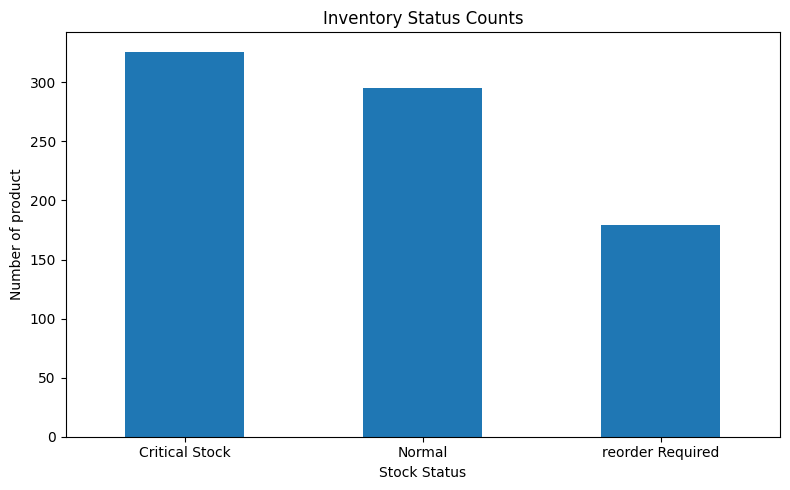

In [180]:
# step 10 - create visualization
status_counts = (
    inventory_report["stock_status"]
    .value_counts()
)
status_counts.plot(
    kind="bar",
    figsize=(8,5)

)
plt.title("Inventory Status Counts")
plt.xlabel("Stock Status")
plt.ylabel("Number of product")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [185]:
# step 11 - Export reports
output_path = Path("outputs")

output_path.mkdir(
    parents=True,
    exist_ok=True
)
inventory_report.to_csv(
    output_path / "inventory_summary.csv",
    index=False
)
low_stock_report.to_csv(
    output_path / "reorder_report.csv",
    index=False
)